# Wildlife Animal Detection in Forest Camera Traps

| | |
|---|---|
| **Goal** | Identify animal species from forest camera-trap images |
| **Concepts** | CNN (transfer learning) and Object Detection (YOLO) |
| **Dataset** | African Wildlife: 1,504 annotated photos of buffalo, elephant, rhino and zebra (about 100 MB), downloaded at runtime |
| **Social relevance** | Supports wildlife conservation and helps reduce human-wildlife conflict |

## Pipeline

1. **Setup**: install libraries, set configuration
2. **Data**: download the dataset (Kaggle or open mirror), pair images with their bounding-box labels
3. **Organise**: stratified train / validation / test split in YOLO format, crop every annotated animal
4. **CNN classifier**: fine-tune an ImageNet-pretrained EfficientNet-B0 to recognise the species of one animal
5. **Evaluate the CNN**: accuracy, per-class report, confusion matrix, sample predictions
6. **YOLO detector**: train YOLOv8 to find and name every animal in a full photo, evaluate with mAP
7. **Combine**: run YOLO, then let the CNN double-check each detected animal

## Before you run
* Use a GPU runtime: **Runtime > Change runtime type > T4 GPU**
* No account is needed by default. Kaggle credentials are only required if you set `DATA_SOURCE = "kaggle"`.

## 1. Setup

In [ ]:
# Install the YOLO library (PyTorch, scikit-learn, pandas, kaggle etc. are preinstalled on Colab)
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 38.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 9.6 MB/s eta 0:00:00


In [ ]:
import os, random, shutil, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

warnings.filterwarnings("ignore")

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "no GPU found")
if DEVICE.type == "cpu":
    print("WARNING: no GPU detected. Training will be very slow. Switch the runtime to GPU.")

Device: cuda | Tesla T4


### Configuration
All tunable settings live in this one cell.

`DATA_SOURCE` chooses where the dataset comes from. Both options are the same **African Wildlife** dataset (about 100 MB, far below the 5 GB limit):
* `"ultralytics"` (default): direct download from the Ultralytics GitHub release. No account needed.
* `"kaggle"`: downloads `biancaferreira/african-wildlife` from Kaggle using your API credentials.

In [ ]:
# ---------------- Dataset ----------------
DATA_SOURCE    = "ultralytics"                    # "ultralytics" (no login) or "kaggle"
KAGGLE_DATASET = "biancaferreira/african-wildlife"
ULTRALYTICS_URL = "https://github.com/ultralytics/assets/releases/download/v0.0.0/african-wildlife.zip"
DATA_DIR       = Path("/content/data")            # raw download
YOLO_DIR       = Path("/content/yolo_data")       # re-organised YOLO train/val/test folders
CROP_DIR       = Path("/content/crops")           # one cropped image per annotated animal (for the CNN)

CLASS_NAMES    = ["buffalo", "elephant", "rhino", "zebra"]   # class ids 0..3 in the label files
NUM_CLASSES    = len(CLASS_NAMES)

# ---------------- CNN classifier training ----------------
IMG_SIZE       = 224
BATCH_SIZE     = 32
EPOCHS         = 8
LEARNING_RATE  = 3e-4
NUM_WORKERS    = 2
USE_AMP        = DEVICE.type == "cuda"            # mixed precision speeds up training on GPU

# ---------------- YOLO detector training ----------------
YOLO_EPOCHS    = 30
YOLO_IMGSZ     = 640
YOLO_BATCH     = 16

## 2. Load the dataset at runtime

**African Wildlife** (original author: Bianca Ferreira, adapted by Ultralytics): 1,504 photographs of **buffalo, elephant, rhino and zebra** in African reserves, each annotated with bounding boxes in YOLO format. It is about 100 MB in total, so it downloads in seconds and trains comfortably on a free Colab GPU.

Because it has bounding boxes, we can train a real **YOLO object detector** on it and also train a **CNN species classifier** on the cropped animals.

### 2.1 Authenticate (Kaggle option only)
If `DATA_SOURCE = "ultralytics"` this step does nothing. For Kaggle, use **one** of:

* **Colab Secrets (recommended):** key icon in the left sidebar, add `KAGGLE_USERNAME` and `KAGGLE_KEY`, and enable notebook access.
* **Upload `kaggle.json`:** create a token at *kaggle.com > Settings > API* and upload it when prompted.

In [ ]:
def setup_kaggle():
    # Option 1: credentials stored in Colab Secrets
    try:
        from google.colab import userdata
        os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
        os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
        print("Kaggle credentials loaded from Colab Secrets.")
        return
    except Exception:
        pass

    # Option 2: kaggle.json already present or uploaded now
    kaggle_dir = Path.home() / ".kaggle"
    kaggle_json = kaggle_dir / "kaggle.json"
    if not kaggle_json.exists():
        from google.colab import files
        print("Secrets not found. Please upload your kaggle.json file.")
        files.upload()
        kaggle_dir.mkdir(exist_ok=True)
        shutil.move("kaggle.json", kaggle_json)
    os.chmod(kaggle_json, 0o600)   # the Kaggle CLI requires restricted permissions
    print("Kaggle credentials ready.")

if DATA_SOURCE == "kaggle":
    setup_kaggle()
else:
    print("DATA_SOURCE is 'ultralytics', no Kaggle login needed.")

DATA_SOURCE is 'ultralytics', no Kaggle login needed.


### 2.2 Download and unzip
The download is skipped if it has already been done in this session.

In [ ]:
DATA_DIR.mkdir(parents=True, exist_ok=True)
done_flag = DATA_DIR / ".downloaded"

if not done_flag.exists():
    if DATA_SOURCE == "kaggle":
        !kaggle datasets download -d {KAGGLE_DATASET} -p {DATA_DIR} --unzip
    else:
        !wget -q -O /content/african-wildlife.zip {ULTRALYTICS_URL}
        !unzip -q -o /content/african-wildlife.zip -d {DATA_DIR}
    done_flag.touch()
else:
    print("Dataset already downloaded, skipping.")

size_mb = sum(f.stat().st_size for f in DATA_DIR.rglob("*") if f.is_file()) / 1e6
n_img = sum(1 for f in DATA_DIR.rglob("*") if f.suffix.lower() in {".jpg", ".jpeg", ".png"})
print(f"Downloaded {n_img:,} images, {size_mb:,.0f} MB")

Downloaded 1,504 images, 105 MB


## 3. Organise the data

The two download sources use different folder layouts, so this step makes them uniform:

1. Pair every image with its YOLO label file (`class x_center y_center width height`, all normalised to 0-1)
2. Check each label is valid and drop images without annotations
3. Create a fresh **70 / 15 / 15** train / validation / test split and write the folder structure and `data.yaml` that YOLO expects

In [ ]:
IMG_EXT = {".jpg", ".jpeg", ".png"}

def parse_label(txt_path):
    # Returns a list of (class_id, xc, yc, w, h), or None if the file is not a valid YOLO label file
    boxes = []
    for line in txt_path.read_text().strip().splitlines():
        parts = line.split()
        if not parts:
            continue
        try:
            c, xc, yc, w, h = int(float(parts[0])), *map(float, parts[1:5])
        except (ValueError, IndexError):
            return None
        if len(parts) != 5 or not (0 <= c < NUM_CLASSES) or not all(0 <= v <= 1 for v in (xc, yc, w, h)):
            return None
        boxes.append((c, xc, yc, w, h))
    return boxes or None

# Index images by their path without extension, then match each label file to its image
images = {p.with_suffix("").as_posix(): p for p in DATA_DIR.rglob("*") if p.suffix.lower() in IMG_EXT}
records = []
for txt in DATA_DIR.rglob("*.txt"):
    key = txt.with_suffix("").as_posix()
    img = images.get(key) or images.get(key.replace("/labels/", "/images/"))   # same folder, or mirrored images/ folder
    boxes = parse_label(txt) if img is not None else None
    if boxes:
        records.append({"image": img, "boxes": boxes, "main_class": boxes[0][0]})

pairs = pd.DataFrame(records)
print(f"Matched {len(pairs):,} images with valid labels ({sum(len(b) for b in pairs.boxes):,} boxes in total)")
assert len(pairs) > 100, "Too few labelled images found. Check the dataset folder layout."

# Stratified split (by the first animal in each image)
train_p, temp_p = train_test_split(pairs, test_size=0.30, stratify=pairs["main_class"], random_state=SEED)
val_p, test_p   = train_test_split(temp_p, test_size=0.50, stratify=temp_p["main_class"], random_state=SEED)
pairs.loc[train_p.index, "split"] = "train"
pairs.loc[val_p.index, "split"] = "val"
pairs.loc[test_p.index, "split"] = "test"

# Write the YOLO folder structure: images/<split>/ and labels/<split>/
if YOLO_DIR.exists():
    shutil.rmtree(YOLO_DIR)
new_paths = []
for n, r in enumerate(pairs.itertuples()):
    name = f"{n:05d}"                                           # unique names avoid collisions between folders
    img_out = YOLO_DIR / "images" / r.split / f"{name}{r.image.suffix.lower()}"
    lbl_out = YOLO_DIR / "labels" / r.split / f"{name}.txt"
    img_out.parent.mkdir(parents=True, exist_ok=True)
    lbl_out.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy(r.image, img_out)
    lbl_out.write_text("\n".join(f"{c} {xc} {yc} {w} {h}" for c, xc, yc, w, h in r.boxes))
    new_paths.append(str(img_out))
pairs["new_path"] = new_paths

# data.yaml tells YOLO where the splits are and what the classes are called
YAML_PATH = YOLO_DIR / "data.yaml"
YAML_PATH.write_text(
    f"path: {YOLO_DIR}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n"
    + "".join(f"  {i}: {n}\n" for i, n in enumerate(CLASS_NAMES))
)
print(pairs["split"].value_counts().to_dict())

Matched 1,504 images with valid labels (2,685 boxes in total)
{'train': 1052, 'test': 226, 'val': 226}


split     train  val  test
species                   
buffalo     377   98    79
elephant    509  113   126
rhino       388   85    86
zebra       583  132   109


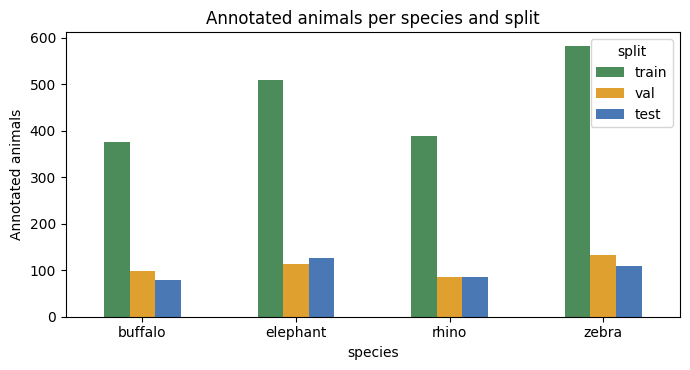

In [ ]:
# Annotated boxes per species and split
box_rows = [{"split": r.split, "species": CLASS_NAMES[b[0]]} for r in pairs.itertuples() for b in r.boxes]
box_counts = pd.DataFrame(box_rows).value_counts().unstack("split").reindex(columns=["train", "val", "test"]).fillna(0).astype(int)
print(box_counts)

ax = box_counts.plot(kind="bar", figsize=(7, 3.8), color=["#4c8c5a", "#e0a030", "#4a78b5"])
ax.set_ylabel("Annotated animals"); ax.set_title("Annotated animals per species and split")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

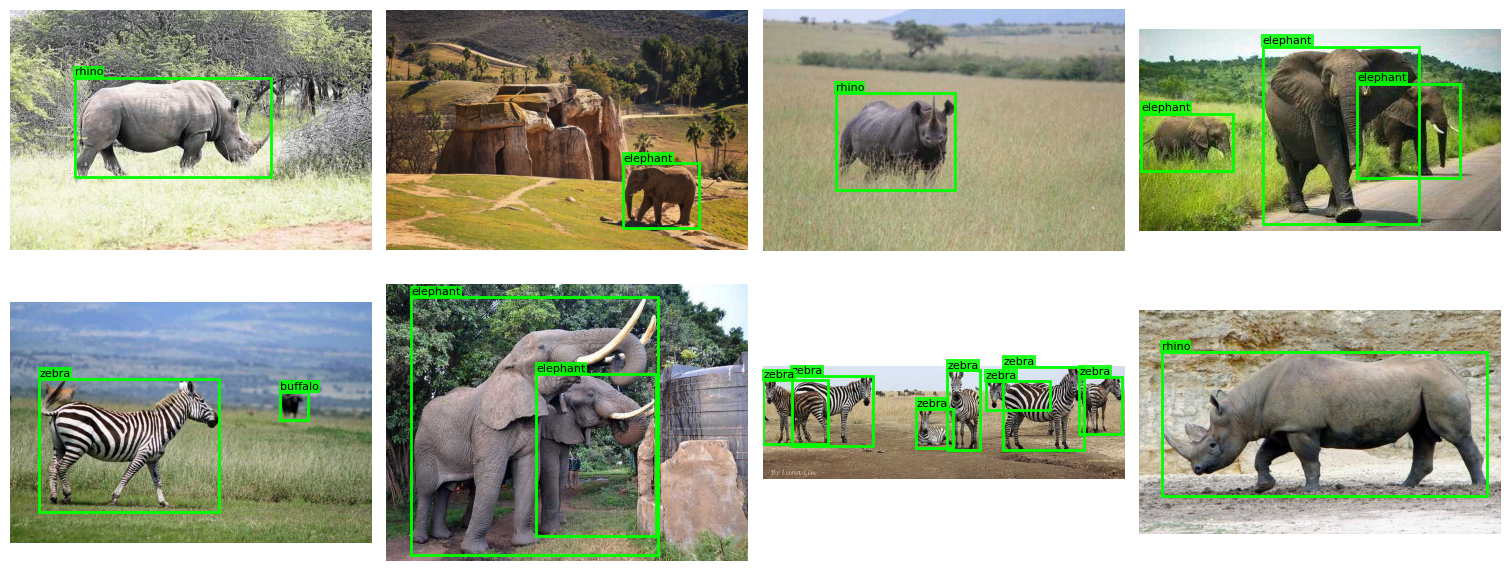

In [ ]:
# Look at ground-truth annotations on a few random training images (this also confirms the class names are right)
def show_ground_truth(n=8, cols=4):
    sample = pairs[pairs["split"] == "train"].sample(n, random_state=SEED)
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3.8 * cols, 3.2 * rows))
    for ax, r in zip(axes.ravel(), sample.itertuples()):
        img = Image.open(r.new_path).convert("RGB")
        W, H = img.size
        ax.imshow(img); ax.axis("off")
        for c, xc, yc, w, h in r.boxes:
            ax.add_patch(patches.Rectangle(((xc - w / 2) * W, (yc - h / 2) * H), w * W, h * H,
                                           fill=False, edgecolor="lime", linewidth=2))
            ax.text((xc - w / 2) * W, (yc - h / 2) * H - 4, CLASS_NAMES[c], color="black", fontsize=8,
                    bbox=dict(facecolor="lime", alpha=0.85, pad=1, edgecolor="none"))
    plt.tight_layout()
    plt.show()

show_ground_truth()

## 4. Crop animals for the CNN classifier

The CNN answers "which species is this animal?", so it needs one image per animal. We cut out every annotated box (with a little padding) and save it under its species.

Crops **inherit the split of their source photo**, so two crops from the same photo can never land in different splits (which would leak information into the test set).

Cropping:   0%|          | 0/1504 [00:00<?, ?it/s]

Crops: 2,667 | train 1,848 | val 422 | test 397


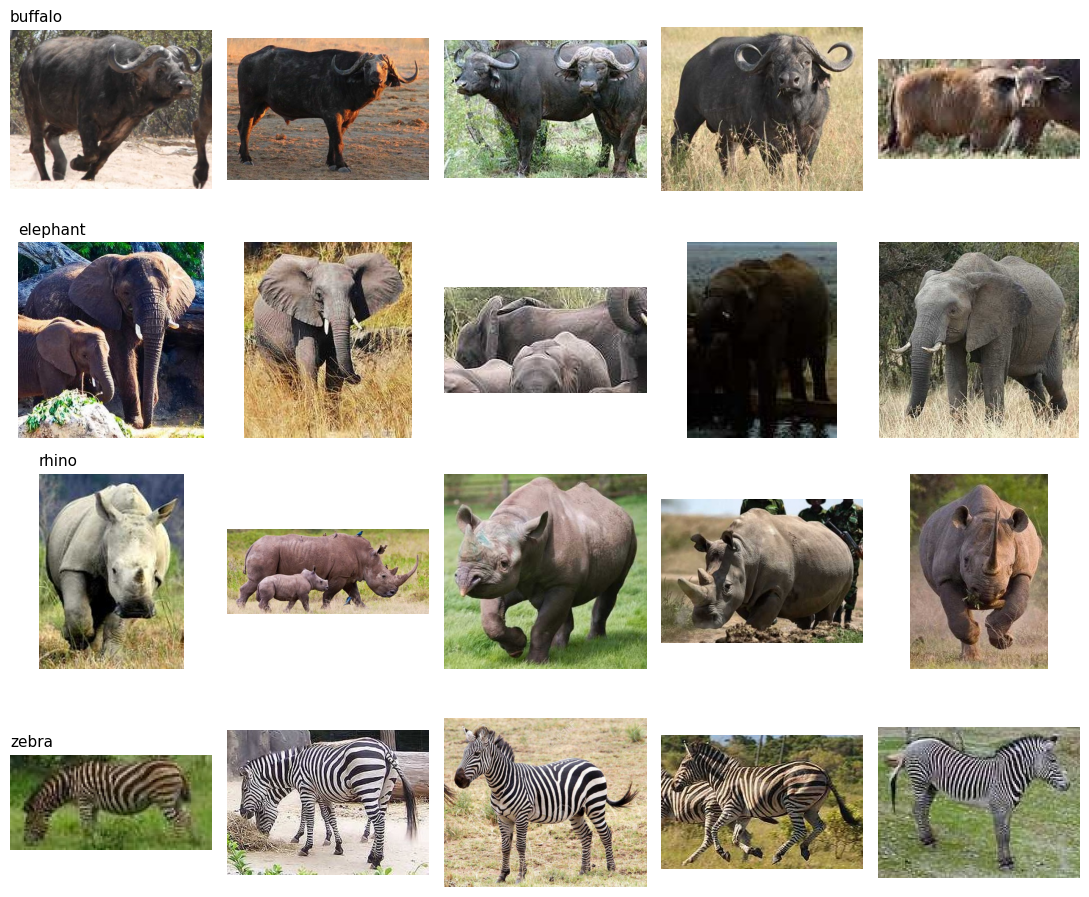

In [ ]:
if CROP_DIR.exists():
    shutil.rmtree(CROP_DIR)

crop_rows = []
for r in tqdm(list(pairs.itertuples()), desc="Cropping"):
    img = Image.open(r.new_path).convert("RGB")
    W, H = img.size
    for j, (c, xc, yc, w, h) in enumerate(r.boxes):
        pad_w, pad_h = 0.05 * w * W, 0.05 * h * H                       # 5% padding around each box
        x1, y1 = max(0, int((xc - w / 2) * W - pad_w)), max(0, int((yc - h / 2) * H - pad_h))
        x2, y2 = min(W, int((xc + w / 2) * W + pad_w)), min(H, int((yc + h / 2) * H + pad_h))
        if x2 - x1 < 32 or y2 - y1 < 32:                                # skip tiny, uninformative crops
            continue
        out = CROP_DIR / r.split / CLASS_NAMES[c] / f"{Path(r.new_path).stem}_{j}.jpg"
        out.parent.mkdir(parents=True, exist_ok=True)
        img.crop((x1, y1, x2, y2)).save(out, quality=95)
        crop_rows.append({"path": str(out), "label": CLASS_NAMES[c], "y": c, "split": r.split})

crop_df = pd.DataFrame(crop_rows)
train_df = crop_df[crop_df["split"] == "train"].reset_index(drop=True)
val_df   = crop_df[crop_df["split"] == "val"].reset_index(drop=True)
test_df  = crop_df[crop_df["split"] == "test"].reset_index(drop=True)

print(f"Crops: {len(crop_df):,} | train {len(train_df):,} | val {len(val_df):,} | test {len(test_df):,}")

# A few crops per species
fig, axes = plt.subplots(NUM_CLASSES, 5, figsize=(11, 2.3 * NUM_CLASSES))
for row, name in zip(axes, CLASS_NAMES):
    for ax, p in zip(row, train_df[train_df["label"] == name].sample(5, random_state=SEED)["path"]):
        ax.imshow(Image.open(p)); ax.axis("off")
    row[0].set_title(name, loc="left", fontsize=11)
plt.tight_layout()
plt.show()

## 5. Data pipeline

Training images get light augmentation (flip, colour jitter, small rotation) to simulate the variation in real camera-trap lighting and animal pose. Validation and test images are only resized and normalised.

In [ ]:
# ImageNet statistics, because the CNN backbone was pretrained on ImageNet
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tfm = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

eval_tfm = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class CameraTrapDataset(Dataset):
    def __init__(self, frame, tfm):
        self.paths = frame["path"].tolist()
        self.labels = frame["y"].tolist()
        self.tfm = tfm

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        try:
            img = Image.open(self.paths[i])
            img.draft("RGB", (IMG_SIZE * 2, IMG_SIZE * 2))   # fast JPEG downscaling while decoding
            img = img.convert("RGB")
        except Exception:
            return self[(i + 1) % len(self)]                 # skip unreadable files
        return self.tfm(img), self.labels[i]

train_loader = DataLoader(CameraTrapDataset(train_df, train_tfm), batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True)
val_loader   = DataLoader(CameraTrapDataset(val_df, eval_tfm), batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True)
test_loader  = DataLoader(CameraTrapDataset(test_df, eval_tfm), batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True)

xb, yb = next(iter(train_loader))
print("Batch shape:", tuple(xb.shape), "| labels:", yb[:8].tolist())

Batch shape: (32, 3, 224, 224) | labels: [1, 3, 2, 2, 2, 3, 1, 3]


## 6. CNN species classifier

**Transfer learning:** we start from EfficientNet-B0 pretrained on ImageNet, replace its final layer with one sized for our species, and fine-tune the whole network. This reaches good accuracy with far less data and compute than training a CNN from scratch.

Class weights in the loss compensate for any remaining imbalance between species.

In [ ]:
# Load the pretrained backbone and swap the classification head
model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, NUM_CLASSES)
model = model.to(DEVICE)

# Class-weighted cross-entropy (rare species count for more)
class_counts = train_df["y"].value_counts().sort_index().values
class_weights = torch.tensor(class_counts.sum() / (NUM_CLASSES * class_counts), dtype=torch.float32).to(DEVICE)
criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 80.5MB/s]


Trainable parameters: 4,012,672


In [ ]:
import copy, time

def run_epoch(loader, train):
    # One pass over a data loader. Updates weights only when train=True.
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in tqdm(loader, leave=False):
            x, y = x.to(DEVICE), y.to(DEVICE)
            with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                out = model(x)
                loss = criterion(out, y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_acc, best_state = 0.0, None

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader, train=False)
    scheduler.step()

    for k, v in zip(history, (tr_loss, va_loss, tr_acc, va_acc)):
        history[k].append(v)

    # Keep the weights from the best validation epoch
    if va_acc > best_val_acc:
        best_val_acc, best_state = va_acc, copy.deepcopy(model.state_dict())

    print(f"Epoch {epoch}/{EPOCHS} | train loss {tr_loss:.3f} acc {tr_acc:.3f} | "
          f"val loss {va_loss:.3f} acc {va_acc:.3f} | {time.time() - t0:.0f}s")

model.load_state_dict(best_state)
print(f"\nBest validation accuracy: {best_val_acc:.3f}")

  0%|          | 0/58 [00:00<?, ?it/s]

  0%|          | 0/14 [00:00<?, ?it/s]

Epoch 1/8 | train loss 0.384 acc 0.892 | val loss 0.132 acc 0.957 | 43s


  0%|          | 0/58 [00:00<?, ?it/s]

  0%|          | 0/14 [00:00<?, ?it/s]

...

  0%|          | 0/58 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a6a06230540>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a6a06230540>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

  0%|          | 0/14 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a6a06230540>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a6a06230540>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
Exception ignored in:     <function _M

Epoch 8/8 | train loss 0.010 acc 0.997 | val loss 0.061 acc 0.991 | 17s

Best validation accuracy: 0.991


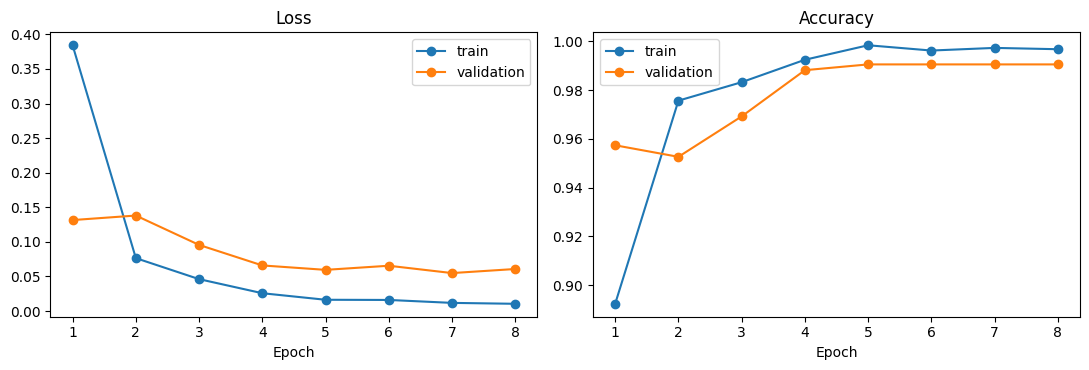

In [ ]:
# Training curves
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
epochs = range(1, len(history["train_loss"]) + 1)

axes[0].plot(epochs, history["train_loss"], marker="o", label="train")
axes[0].plot(epochs, history["val_loss"], marker="o", label="validation")
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend()

axes[1].plot(epochs, history["train_acc"], marker="o", label="train")
axes[1].plot(epochs, history["val_acc"], marker="o", label="validation")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend()

plt.tight_layout()
plt.show()

## 7. Evaluation on the held-out test set
The test set was never used for training or model selection, so these numbers estimate real-world performance.

In [ ]:
@torch.no_grad()
def predict_loader(loader):
    # Returns class probabilities and true labels for every sample in the loader
    model.eval()
    all_probs, all_y = [], []
    for x, y in tqdm(loader, leave=False):
        probs = torch.softmax(model(x.to(DEVICE)).float(), dim=1).cpu()
        all_probs.append(probs)
        all_y.append(y)
    return torch.cat(all_probs), torch.cat(all_y)

probs, y_true = predict_loader(test_loader)
y_pred = probs.argmax(1)

top1 = (y_pred == y_true).float().mean().item()
k = min(3, NUM_CLASSES)
top_k = (probs.topk(k, dim=1).indices == y_true[:, None]).any(dim=1).float().mean().item()

print(f"Test top-1 accuracy: {top1:.3f}")
print(f"Test top-{k} accuracy: {top_k:.3f}\n")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=3))

  0%|          | 0/13 [00:00<?, ?it/s]

Test top-1 accuracy: 0.982
Test top-3 accuracy: 1.000

              precision    recall  f1-score   support

     buffalo      0.987     0.949     0.968        79
    elephant      0.969     0.984     0.976       125
       rhino      0.977     1.000     0.988        84
       zebra      1.000     0.991     0.995       109

    accuracy                          0.982       397
   macro avg      0.983     0.981     0.982       397
weighted avg      0.983     0.982     0.982       397



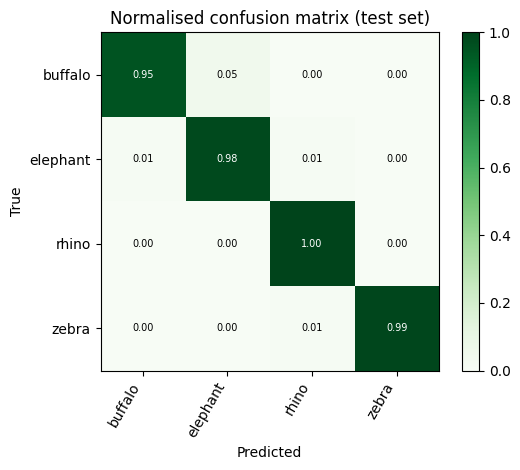

In [ ]:
# Confusion matrix (rows = true species, columns = predicted species)
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(0.7 * NUM_CLASSES + 3, 0.7 * NUM_CLASSES + 2))
im = ax.imshow(cm_norm, cmap="Greens", vmin=0, vmax=1)
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=60, ha="right")
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Normalised confusion matrix (test set)")
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, f"{cm_norm[i, j]:.2f}", ha="center", va="center",
                color="white" if cm_norm[i, j] > 0.5 else "black", fontsize=7)
plt.colorbar(im, fraction=0.046)
plt.tight_layout()
plt.show()

In [ ]:
# Sample predictions: green title = correct, red title = wrong
def show_predictions(n=8, cols=4):
    idx = np.random.RandomState(SEED).choice(len(test_df), n, replace=False)
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3.6 * cols, 3.2 * rows))
    for ax, i in zip(axes.ravel(), idx):
        r = test_df.iloc[i]
        ax.imshow(Image.open(r["path"]).convert("RGB"))
        pred, conf = CLASS_NAMES[y_pred[i]], probs[i].max().item()
        ok = pred == r["label"]
        ax.set_title(f"{pred} ({conf:.0%})\ntrue: {r['label']}", fontsize=9, color="green" if ok else "red")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_predictions()

## 8. Object detection with YOLO

The CNN above names the species of a **single animal crop**. A detector works on the **whole photo**: it finds every animal, draws a box around it and names the species in one pass, so it also copes with herds and several species in one frame.

We fine-tune **YOLOv8n** (COCO-pretrained) on our annotated photos. YOLO is itself a CNN, trained end to end to predict boxes and classes.

In [ ]:
from ultralytics import YOLO

# Start from COCO-pretrained weights (downloaded automatically) and fine-tune on our data
detector = YOLO("yolov8n.pt")
train_results = detector.train(
    data=str(YAML_PATH),
    epochs=YOLO_EPOCHS,
    imgsz=YOLO_IMGSZ,
    batch=YOLO_BATCH,
    project="/content/runs",
    name="wildlife",
    exist_ok=True,      # overwrite earlier runs of this notebook
    seed=SEED,
    workers=NUM_WORKERS,
    patience=10,        # stop early if validation stops improving
    plots=True,
    verbose=False,
)

best_weights = Path(detector.trainer.best)   # weights from the best validation epoch
save_dir = Path(detector.trainer.save_dir)
print("Best weights:", best_weights)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_data/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, fr

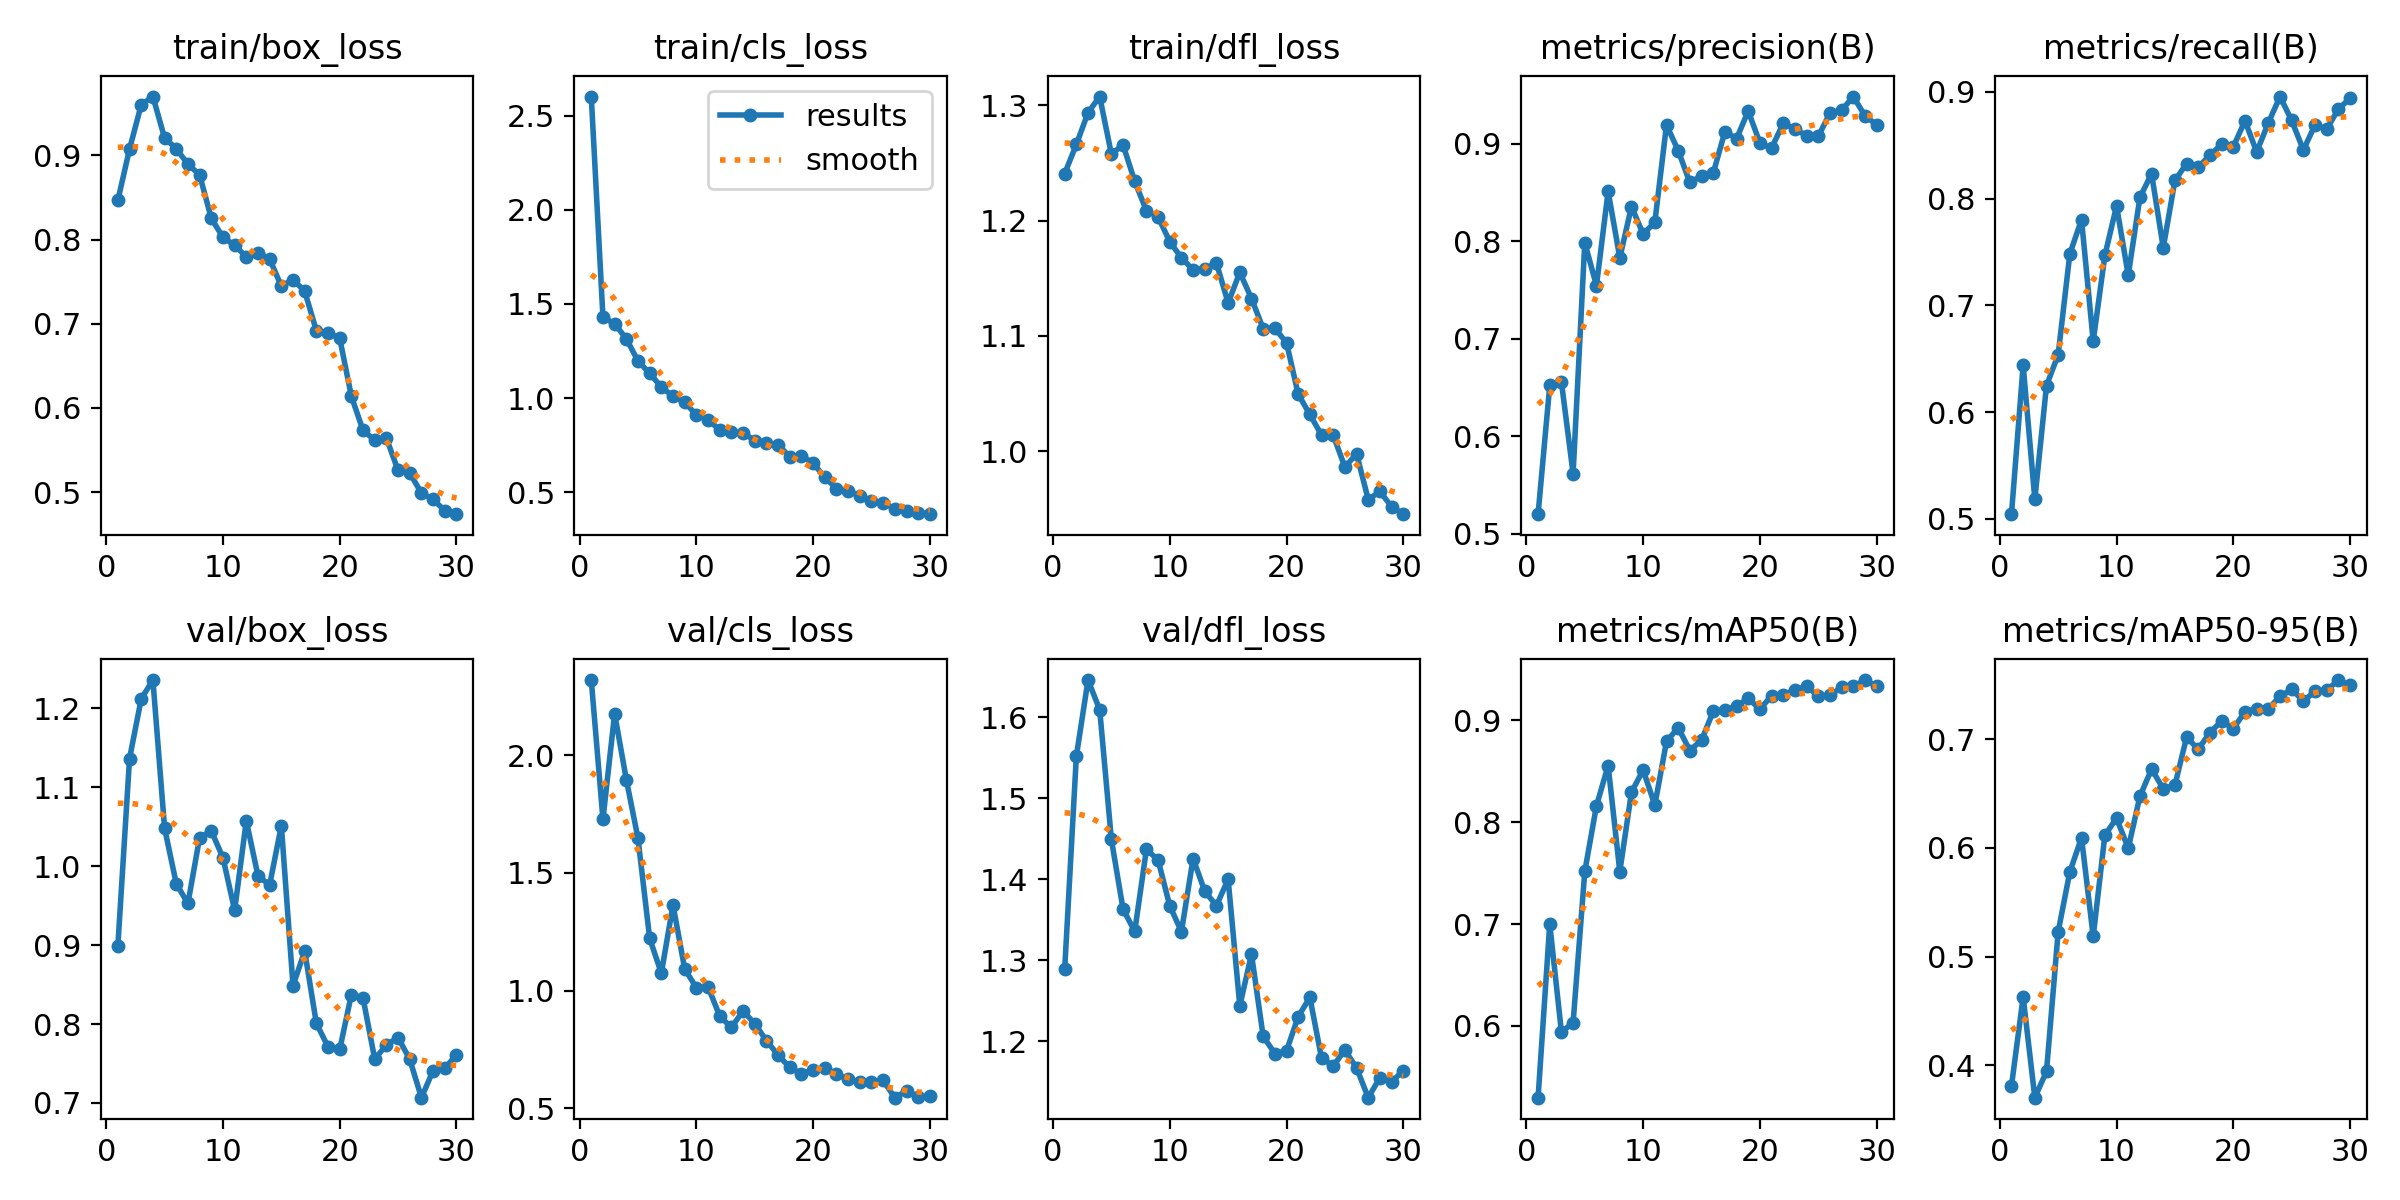

In [ ]:
# Training curves recorded by YOLO (box / class loss, precision, recall, mAP)
from IPython.display import Image as IPyImage, display
display(IPyImage(filename=str(save_dir / "results.png"), width=900))

### 8.1 Evaluate the detector on the test set
Detection is scored with **mAP** (mean average precision): a predicted box counts as correct only if it overlaps the true box enough (IoU) **and** has the right species.
* **mAP@50**: correct when IoU is at least 0.5
* **mAP@50-95**: average over stricter IoU thresholds from 0.5 to 0.95 (the harder, standard COCO metric)

In [ ]:
detector = YOLO(best_weights)
metrics = detector.val(data=str(YAML_PATH), split="test", imgsz=YOLO_IMGSZ, plots=False, verbose=False)

print(f"Test precision : {metrics.box.mp:.3f}")
print(f"Test recall    : {metrics.box.mr:.3f}")
print(f"Test mAP@50    : {metrics.box.map50:.3f}")
print(f"Test mAP@50-95 : {metrics.box.map:.3f}\n")

print("mAP@50-95 per species:")
for name, m in zip(CLASS_NAMES, metrics.box.maps):
    print(f"  {name:<10} {m:.3f}")

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,006,428 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2191.3±821.1 MB/s, size: 99.6 KB)
val: Scanning /content/yolo_data/labels/test... 226 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 226/226 1.9Kit/s 0.1s
val: New cache created: /content/yolo_data/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 6.5it/s 2.3s
                   all        226        400      0.935      0.875      0.943      0.788
Speed: 0.9ms preprocess, 4.3ms inference, 0.0ms loss, 1.4ms postprocess per image
Test precision : 0.935
Test recall    : 0.875
Test mAP@50    : 0.943
Test mAP@50-95 : 0.788

mAP@50-95 per species:
  buffalo    0.816
  elephant   0.744
  rhino      0.820
  zebra      0.771


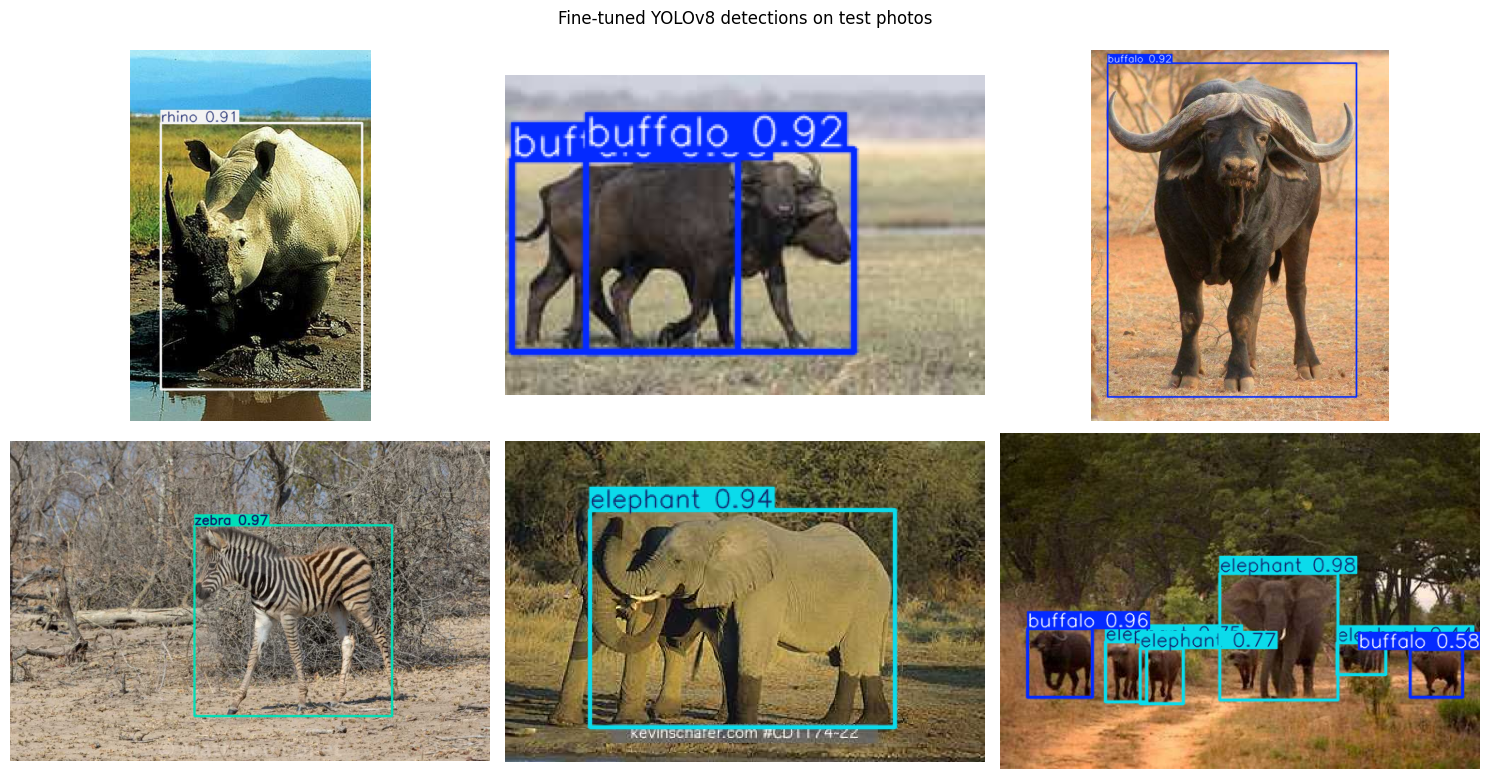

In [ ]:
# Detector predictions on random test photos
test_imgs = sorted((YOLO_DIR / "images" / "test").glob("*"))
demo = [test_imgs[i] for i in np.random.RandomState(SEED).choice(len(test_imgs), 6, replace=False)]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, p in zip(axes.ravel(), demo):
    result = detector.predict(str(p), conf=0.25, verbose=False)[0]
    ax.imshow(result.plot()[..., ::-1])   # plot() returns BGR, convert to RGB
    ax.axis("off")
plt.suptitle("Fine-tuned YOLOv8 detections on test photos", y=0.99)
plt.tight_layout()
plt.show()

### 8.2 Combine detector and CNN
For every box YOLO finds, we crop the animal and let the CNN from Section 6 give a second opinion on the species. Showing both labels (`YOLO / CNN`) lets us check how often the two independent models agree, which is useful when no ground truth exists for new photos.

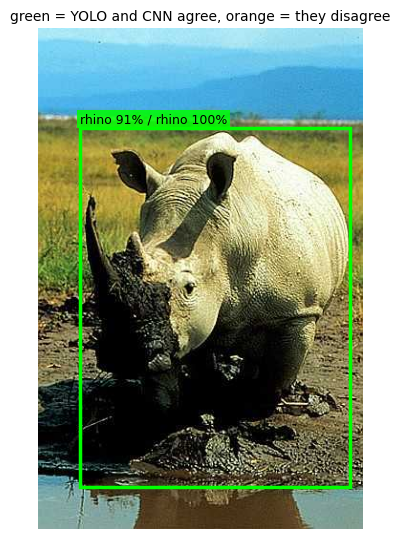

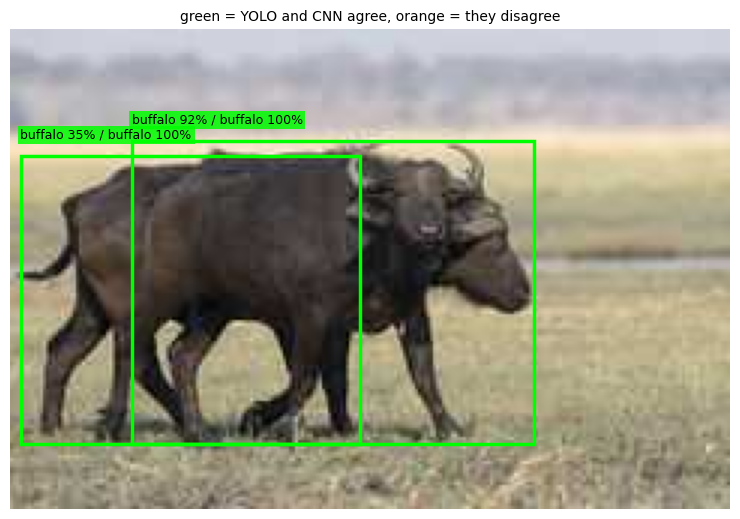

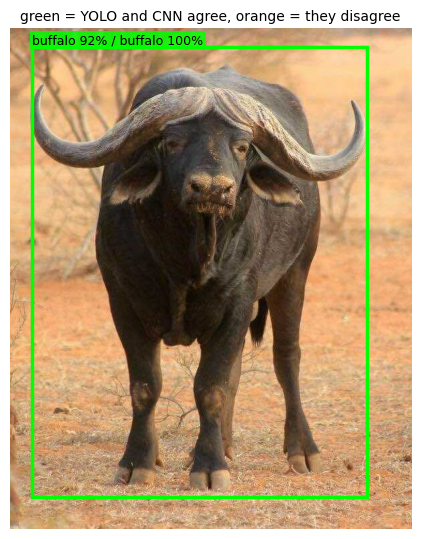

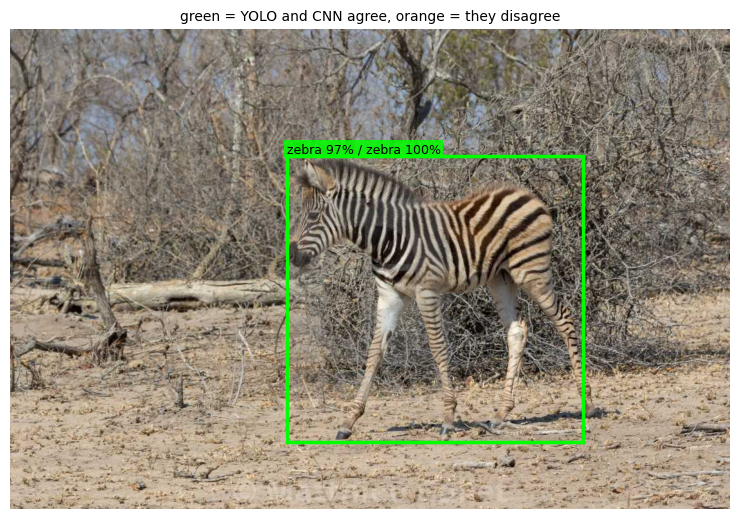

In [ ]:
@torch.no_grad()
def classify_pil(img):
    # Species prediction for a single PIL image
    model.eval()
    x = eval_tfm(img).unsqueeze(0).to(DEVICE)
    p = torch.softmax(model(x).float(), dim=1)[0].cpu()
    k = p.argmax().item()
    return CLASS_NAMES[k], p[k].item()

def detect_and_classify(path, det_conf=0.25, show=True):
    img = Image.open(path).convert("RGB")
    result = detector.predict(img, conf=det_conf, verbose=False)[0]

    detections = []
    for box, cls, conf in zip(result.boxes.xyxy.tolist(), result.boxes.cls.tolist(), result.boxes.conf.tolist()):
        x1, y1, x2, y2 = map(int, box)
        cnn_species, cnn_conf = classify_pil(img.crop((x1, y1, x2, y2)))
        detections.append({"box": (x1, y1, x2, y2), "yolo": CLASS_NAMES[int(cls)], "yolo_conf": conf,
                           "cnn": cnn_species, "cnn_conf": cnn_conf})

    if show:
        fig, ax = plt.subplots(figsize=(7.5, 5.5))
        ax.imshow(img); ax.axis("off")
        for d in detections:
            x1, y1, x2, y2 = d["box"]
            agree = d["yolo"] == d["cnn"]
            colour = "lime" if agree else "orange"
            ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=colour, linewidth=2.5))
            ax.text(x1, max(y1 - 6, 12), f"{d['yolo']} {d['yolo_conf']:.0%} / {d['cnn']} {d['cnn_conf']:.0%}",
                    color="black", fontsize=9, bbox=dict(facecolor=colour, alpha=0.85, pad=2, edgecolor="none"))
        ax.set_title("green = YOLO and CNN agree, orange = they disagree", fontsize=10)
        plt.tight_layout()
        plt.show()
    return detections

for p in demo[:4]:
    detect_and_classify(p)

In [ ]:
# How often do the two models agree on the species of each detected animal? (test photos)
total = agree = 0
for p in tqdm(test_imgs, leave=False):
    for d in detect_and_classify(p, show=False):
        total += 1
        agree += d["yolo"] == d["cnn"]

print(f"Species agreement between YOLO and CNN: {agree}/{total} detections ({agree / max(total, 1):.1%})")

  0%|          | 0/226 [00:00<?, ?it/s]

Species agreement between YOLO and CNN: 415/431 detections (96.3%)


## 9. Save the models

In [ ]:
# CNN classifier together with its class list. The YOLO weights are already saved at best_weights.
torch.save({"state_dict": model.state_dict(), "class_names": CLASS_NAMES, "img_size": IMG_SIZE},
           "/content/species_classifier.pt")
print("Saved /content/species_classifier.pt")
print("YOLO weights:", best_weights)

# Optional: download them to your computer
# from google.colab import files
# files.download("/content/species_classifier.pt")
# files.download(str(best_weights))

Saved /content/species_classifier.pt
YOLO weights: /content/runs/wildlife/weights/best.pt


## 10. Summary and discussion

**What we built**
* A **YOLOv8** detector fine-tuned on bounding-box annotations that finds and names buffalo, elephants, rhinos and zebras in whole photographs, evaluated with precision, recall and mAP on a held-out test set.
* A transfer-learning **CNN** (EfficientNet-B0) that classifies cropped animals, evaluated with accuracy, a per-class report and a confusion matrix.
* A combined pipeline in which both models label each detection, giving an agreement check between two independent models.

**Limitations**
* The dataset is small (about 1,500 photos, 4 species), so results will not transfer directly to real camera-trap footage with night-time infrared frames, motion blur, partial occlusion and animals far from the camera.
* Many images are well-framed photographs rather than automatic camera-trap captures, so the task is easier than deployment conditions.
* Only four species are covered, and there is no "empty frame" class, although most real camera-trap frames are empty.
* The source dataset does not specify a licence, so it is suitable for coursework and research but should be checked before any commercial use.

**Possible improvements**
* Train on true camera-trap data such as Snapshot Serengeti, Caltech Camera Traps or iWildCam (available as subsets), and add background and empty images.
* Use a larger YOLO model, longer training and stronger augmentation (brightness changes, mosaic, grayscale for infrared).
* Add object tracking across consecutive frames to count individuals rather than detections.

**Social relevance**
Automating species identification replaces thousands of hours of manual labelling, so conservation teams can monitor populations, detect disturbance linked to poaching and understand animal movement much faster. Reliable detection near villages and farmland can also feed early-warning alerts that reduce human-wildlife conflict.

**Data citation:** Ferreira, B., *African Wildlife* dataset (Kaggle: `biancaferreira/african-wildlife`), adapted for Ultralytics YOLO.